In [1]:
import wandb
import json
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rc
rc('text', usetex=True)
import matplotlib.pylab as pylab
params = {'legend.fontsize': '11',
          'figure.figsize': (6,5),
          'axes.labelsize': 18,
          'axes.titlesize': 18,
          'xtick.labelsize': 13,
          'ytick.labelsize': 13}
pylab.rcParams.update(params)
import numpy as np
from scipy.stats import gaussian_kde

import glob
import pickle
import jax
from scipy.ndimage import gaussian_filter
import tqdm
from tqdm import trange
import scipy.stats as st


In [2]:
sample_data=pickle.load(open('LLZO/llzo_11_45/sampler_lbfgs/sampling_run_11.bp','rb'))

/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_25772/3940086966.py:1: DeprecationWarning: Pickled array contains an aval with a named_shape attribute. This is deprecated and the code path supporting such avals will be removed. Please re-pickle the array.
  sample_data=pickle.load(open('LLZO/llzo_11_45/sampler_lbfgs/sampling_run_11.bp','rb'))


dict_keys(['system_name', 'optimised_structure', 'local_minimum_energy', 'initial_optimisation_succeed', 'energy_unit', 'molecular_dynamics'])
dict_keys(['md_succeed', 'phonon_energies', 'phonon_dos', 'fvib', 'internal_energy'])
-7.820344396751493


(0.0, 100.0)

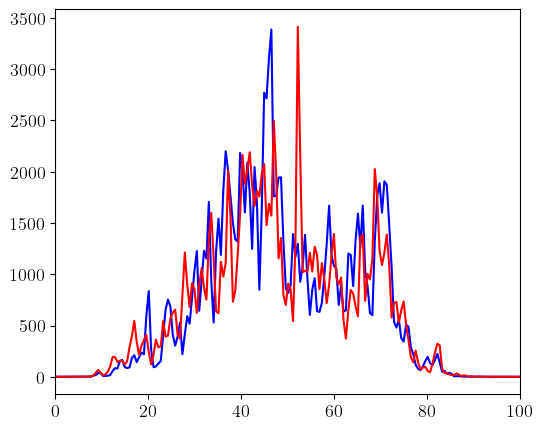

In [3]:
print(sample_data[2].keys())
print(sample_data[2]['molecular_dynamics'][300].keys())
print(sample_data[2]['molecular_dynamics'][300]['internal_energy'])
#x=[_x/1e3 for _x in sample_data[2]['molecular_dynamics'][300]['phonon_energies']]
x=sample_data[2]['molecular_dynamics'][300]['phonon_energies']
plt.plot(x,sample_data[2]['molecular_dynamics'][300]['phonon_dos'],'b-')
plt.plot(x,sample_data[8]['molecular_dynamics'][300]['phonon_dos'],'r-')
plt.xlim([0,100])

/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_25772/3900886848.py:5: RuntimeWarning: divide by zero encountered in scalar divide
  normaised_pdos=[pdos[i]/(x[i]**2) for i in range(len(pdos))]


(0.0, 4.835981008048)

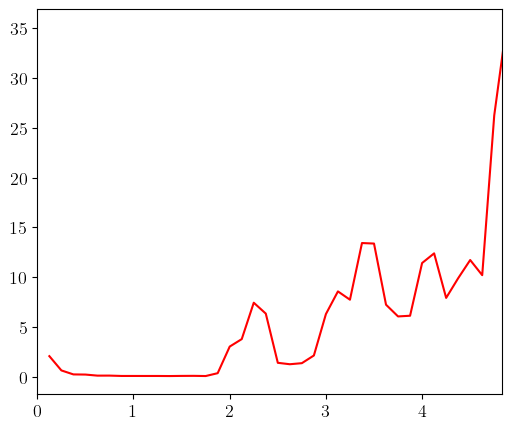

In [8]:
#try to see if there is a boson peak in the VDOS for  LLZO
x=sample_data[2]['molecular_dynamics'][300]['phonon_energies']
x=[_x*0.2417990504024 for _x in x]
pdos=sample_data[2]['molecular_dynamics'][300]['phonon_dos']
#plt.plot(x,pdos,'b-')
normaised_pdos=[pdos[i]/(x[i]**2) for i in range(len(pdos))]
plt.plot(x,normaised_pdos,'r-')
plt.xlim([0,20*0.2417990504024])

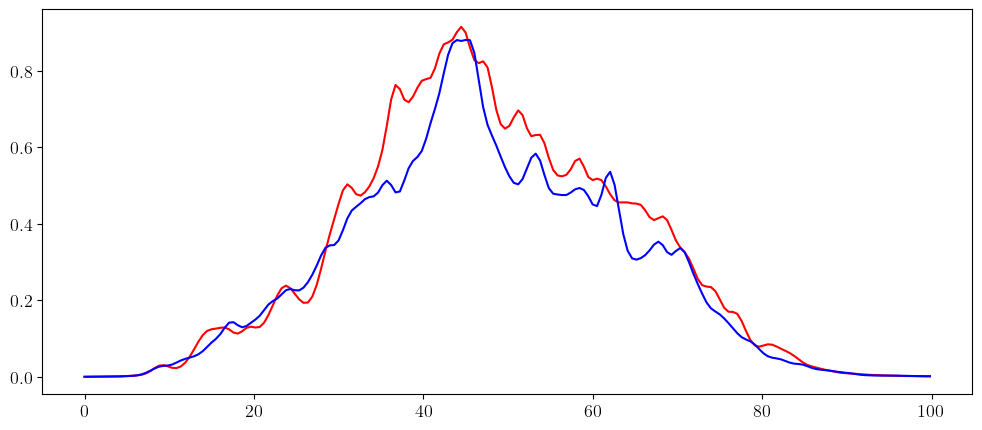

In [196]:
def tidy_data(phonon_energies,phonon_dos):
    #phonon_energies=[_x/1e3 for _x in phonon_energies]
    truncated_phonon_energies=[_x for _x in phonon_energies if _x<=100]
    truncated_phonon_dos=[phonon_dos[i] for i in range(len(phonon_energies)) if phonon_energies[i]<=100]
    ph_dos = [i / max(truncated_phonon_dos) for i in truncated_phonon_dos]
    ph_dos = gaussian_filter(ph_dos, sigma=1.5)
    #print(len(truncated_phonon_energies),len(truncated_phonon_dos),len(ph_dos))
    return truncated_phonon_energies,ph_dos

e,dos=tidy_data(sample_data[9]['molecular_dynamics'][1500]['phonon_energies'],sample_data[9]['molecular_dynamics'][1500]['phonon_dos'])
plt.plot(e,dos,'r-')
e,dos=tidy_data(sample_data[5]['molecular_dynamics'][1500]['phonon_energies'],sample_data[5]['molecular_dynamics'][1500]['phonon_dos'])

plt.plot(e,dos,'b-')

In [169]:
from tqdm import trange

temp=300
kT=8.6173303e-5*temp

all_data=glob.glob('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_*.bp')
all_dos=[]
internal_energies=[]
for i in trange(len(all_data)):
    data=pickle.load(open('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))
    for j in range(len(data)):
        energy=data[j]['molecular_dynamics'][temp]['phonon_energies']
        dos=data[j]['molecular_dynamics'][temp]['phonon_dos']
        energy,dos=tidy_data(energy,dos)
        internal_energy=data[j]['molecular_dynamics'][temp]['internal_energy']
        internal_energies.append(internal_energy)
        all_dos.append(dos)

#min_energy=min(internal_energies)
#internal_energies=[i-min_energy for i in internal_energies]
denominator=np.sum([np.exp(-internal_energies[i]/kT) for i in range(len(internal_energies))])
print(denominator)

weight_dos=[]
for i in trange(len(internal_energies)):
    weight_dos.append(all_dos[i]*np.exp(-internal_energies[i]/kT)/denominator)
    

all_dos=np.array(all_dos)
print(np.shape(all_dos))

  0%|                                                                                                | 0/417 [00:00<?, ?it/s]/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_5121/1991913980.py:10: DeprecationWarning: Pickled array contains an aval with a named_shape attribute. This is deprecated and the code path supporting such avals will be removed. Please re-pickle the array.
  data=pickle.load(open('LLZO/llzo_12_44/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))
100%|██████████████████████████████████████████████████████████████████████████████████████| 417/417 [00:26<00:00, 15.53it/s]


9.872104663915185e+134


100%|████████████████████████████████████████████████████████████████████████████████| 4161/4161 [00:00<00:00, 165080.72it/s]


(4161, 194)


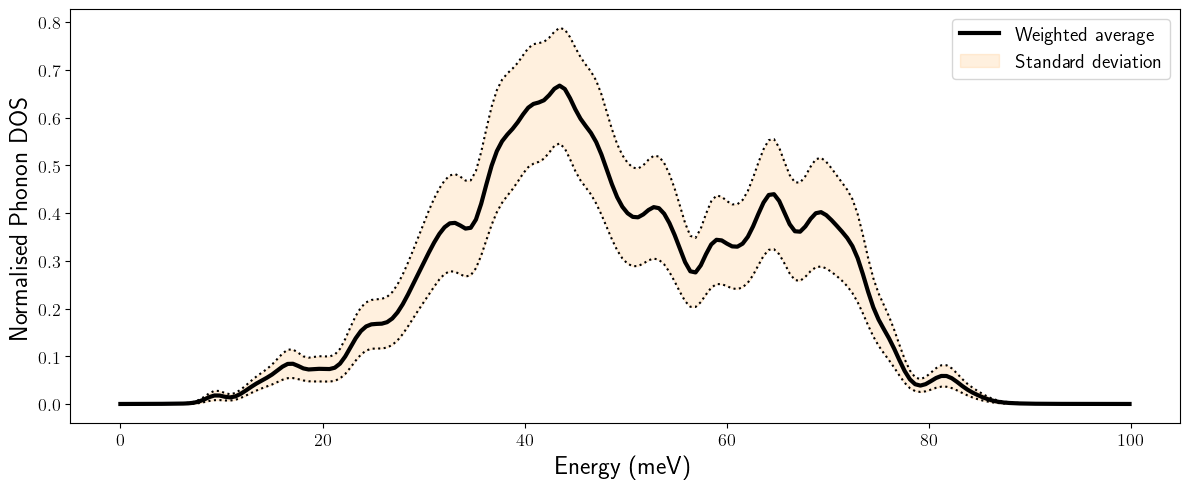

In [170]:
max_dos=np.max(weight_dos)
weight_dos=weight_dos/max_dos

average=np.mean(weight_dos,axis=0)
std=np.std(weight_dos,axis=0)
plt.plot(energy,average,'-',lw=3,c='k',label='Weighted average')

plus=plt.plot(energy,average+std,'k:')
minus=plt.plot(energy,average-std,'k:')
plt.fill_between(energy,average+std,average-std,color='#FFB55A',alpha=0.2,label='Standard deviation')
plt.legend(fontsize=14)
plt.xlabel('Energy (meV)')
plt.ylabel('Normalised Phonon DOS')
plt.tight_layout()
plt.savefig('12_44_configuration_averaged_PDOS_'+str(temp)+'.pdf')

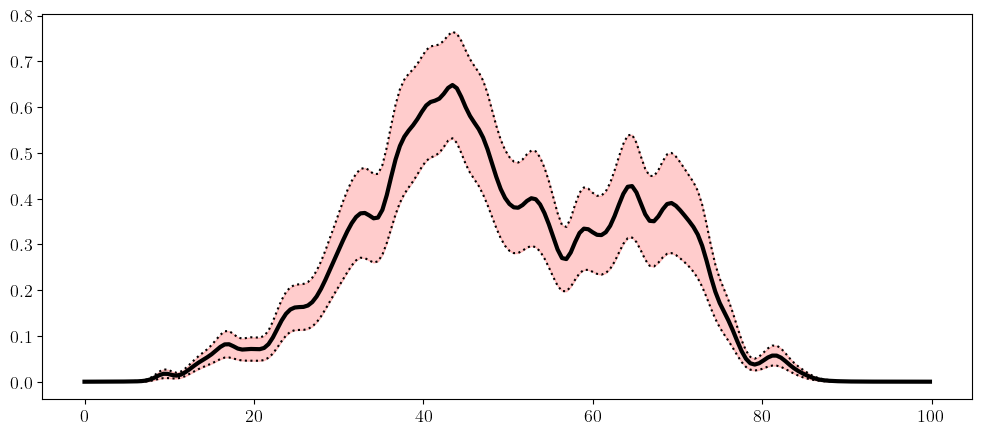

In [9]:
average=np.mean(all_dos,axis=0)
std=np.std(all_dos,axis=0)
plt.plot(energy,average,'k-',lw=3)
plus=plt.plot(energy,average+std,'k:')
minus=plt.plot(energy,average-std,'k:')
plt.fill_between(energy,average+std,average-std,color='r',alpha=0.2)

In [ ]:
import glob
import scipy.stats as st
temp=300

Natoms=56+96+24+16

d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_last_frame_large_nn_high_wf.npz',allow_pickle=True))
x=dict(enumerate(d['targets'].flatten()))[0]['E'].flatten()
x=list(sorted(x))
x=[_x/Natoms for  _x in x]
_x_dft=np.arange(min(x)-0.001,max(x),0.00005)

all_data=glob.glob('./LLZO/llzo_12_44/sampler_lbfgs/*.log')
x=[]
for data in all_data:
    df=open(data,'r')
    for line in df.readlines():
        if 'Energy of optimised structure' in line:
            x.append(float(line.split()[-1]))
x=list(sorted(x))
x=[_x/Natoms for  _x in x]
print(len(x))

kernel = st.gaussian_kde(x)
#plt.plot(_x_dft,kernel(_x_dft),'-',c='#DB74AB',lw=4,label='Predicted distribution (MLFF)')
#plt.xlim([-1505.6/Natoms,-1504.4/Natoms])

In [9]:
all_data=glob.glob('LLZO/llzo_11_45/sampler_lbfgs/sampling_run_*.bp')
all_dos=[]
internal_energies_300=[]
internal_energies_1500=[]
fvibs_300=[]
fvibs_1500=[]
local_minima=[]
for i in trange(len(all_data)):
    data=pickle.load(open('LLZO/llzo_11_45/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))
    for j in range(len(data)):
        try:
            local_minima.append(data[j]['local_minimum_energy'])
            internal_energy=data[j]['molecular_dynamics'][300]['internal_energy']
            fvib=data[j]['molecular_dynamics'][300]['fvib']
            if (internal_energy is not None) and (fvib is not None):
                internal_energies_300.append(internal_energy)
                fvibs_300.append(fvib)
    
            internal_energy=data[j]['molecular_dynamics'][1500]['internal_energy']
            fvib=data[j]['molecular_dynamics'][1500]['fvib']
            if (internal_energy is not None) and (fvib is not None):
                internal_energies_1500.append(internal_energy)
                fvibs_1500.append(fvib)
        except:
            pass
        
total_fvib_300=[]
total_fvib_1500=[]
for i in trange(len(fvibs_300)):
    total_fvib_300.append(internal_energies_300[i]-fvibs_300[i])
    total_fvib_1500.append(internal_energies_1500[i]-fvibs_1500[i])

print(len(fvibs_300))
#internal_energies=list(sorted(internal_energies))
#kernel = st.gaussian_kde(internal_energies)
#
#plt.plot(internal_energies,kernel(internal_energies),'-',c='b',lw=2,label='')
#

  0%|                                                                                               | 0/3298 [00:00<?, ?it/s]/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_71360/3206530356.py:9: DeprecationWarning: Pickled array contains an aval with a named_shape attribute. This is deprecated and the code path supporting such avals will be removed. Please re-pickle the array.
  data=pickle.load(open('LLZO/llzo_11_45/sampler_lbfgs/sampling_run_'+str(i)+'.bp','rb'))
100%|█████████████████████████████████████████████████████████████████████████████| 65948/65948 [00:00<00:00, 1412855.17it/s]

65948


-7.744435003193705 -7.140234001672794
11
-7.821719804694681 -7.140234001672794


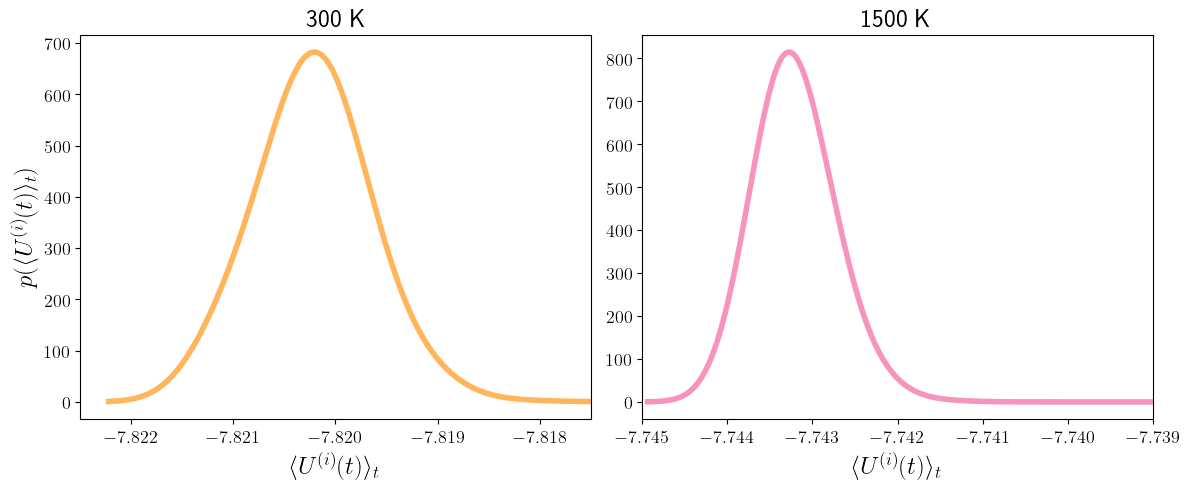

In [19]:
fig, (ax1,ax2)= plt.subplots(1,2,figsize=(12,5))
kernel = st.gaussian_kde(internal_energies_1500)
print(min(internal_energies_1500),max(internal_energies_1500))
x=np.arange(min(internal_energies_1500)-0.0005,max(internal_energies_1500)+0.0005,0.00001)

print(len([_x for _x in internal_energies_1500 if _x>-7.739]))

ax2.plot(x,kernel(x),'-',c='#F694BD',lw=4,label='')
ax2.set_xlim([-7.745,-7.739])

ax2.set_title('1500 K')
ax2.set_xlabel('$\langle U^{(i)}(t) \\rangle_t$')

kernel = st.gaussian_kde(internal_energies_300)
print(min(internal_energies_300),max(internal_energies_300))

x=np.arange(min(internal_energies_300)-0.0005,max(internal_energies_300)+0.0005,0.00001)
ax1.plot(x,kernel(x),'-',c='#FFB55A',lw=4,label='')
ax1.set_xlim([-7.8225,-7.8175])

ax1.set_title('300 K')
ax1.set_xlabel('$\langle U^{(i)}(t) \\rangle_t$')
ax1.set_ylabel('$p(\langle U^{(i)}(t) \\rangle_t)$')

plt.tight_layout()
plt.savefig('11_45_internal_energy_distributions.pdf')

1500 K <F_vib>_T: -9.092919115891315


100%|█████████████████████████████████████████████████████████████████████████████████| 4160/4160 [00:00<00:00, 34921.61it/s]


S_{conf+vib}: 0.0006862690333190566
-TS_{conf+vib}: -1.029403549978585
G: -10.1223226658699
300 K <F_vib>_T: -8.107252857088884


100%|█████████████████████████████████████████████████████████████████████████████████| 4160/4160 [00:00<00:00, 44861.98it/s]


S_{conf+vib}: 0.000657823605293157
-TS_{conf+vib}: -0.19734708158794712
G: -8.304599938676832


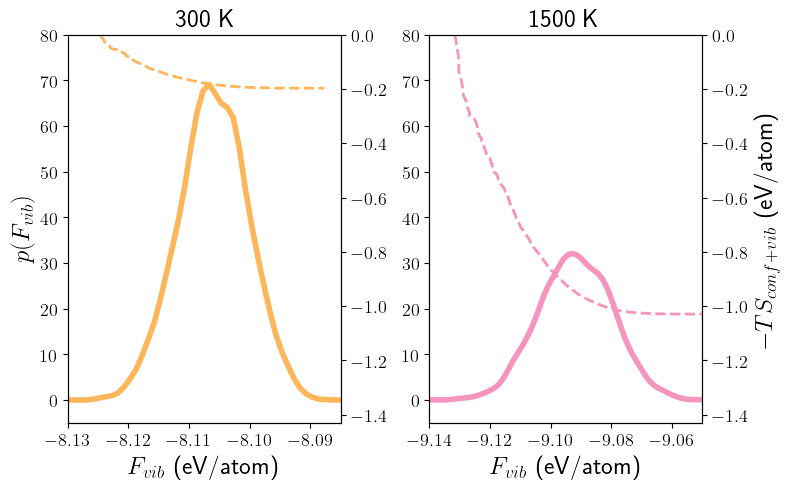

In [127]:
import math

k=8.6173303e-5

fig, (ax2,ax1)=plt.subplots(1,2,figsize=(8,5))
#fig.subplots_adjust(wspace=0.3)  # adjust space between Axes


total_fvib_1500=list(sorted(total_fvib_1500))

xmin=min(total_fvib_1500)
E_exp=sum([j*math.exp(-(j-xmin)/(k*1500)) for j in total_fvib_1500])/sum([math.exp(-(j-xmin)/(k*1500)) for j in total_fvib_1500])
print("1500 K <F_vib>_T: "+str(E_exp))

kernel = st.gaussian_kde(total_fvib_1500)
x=np.arange(min(total_fvib_1500)-0.005,max(total_fvib_1500)+0.005,0.0005)
ax1.plot(x,kernel(x),'-',c='#F694BD',lw=4,label='')
ax1.set_xlim([-9.14,-9.05])
ax1.set_ylim([-5,80])

#ax1.set_ylabel('$p(F_{vib})$')
ax1.set_xlabel('$F_{vib}$ (eV/atom)')

free_energies=[]
xmin=min(total_fvib_1500)
xx=np.array([i-xmin for i in total_fvib_1500]) #partition function should be measured with respect to the global minimum in the ensemble
for i in trange(1,len(xx)):
    _xx=np.array(xx[:i])
    _zz=np.exp(-1.0*_xx/(1500*k))
    Z=np.sum(_zz)
    
    #Z=sum([math.exp(-1.0*j/(1500*k)) for j in xx[:i]])
    free_energies.append(-k*1500*math.log(Z))

print('S_{conf+vib}: '+str(free_energies[-1]/(-1500)))
print('-TS_{conf+vib}: '+str(free_energies[-1]))
print('G: '+str(free_energies[-1]+E_exp))

ax1_1 = ax1.twinx() 
ax1_1.plot(total_fvib_1500[1:],free_energies,'--',lw=2,c='#F694BD')

ax1_1.set_ylim([-1.43,0.0])
ax1_1.set_ylabel('$-TS_{conf+vib}$ (eV/atom)')

ax1.set_title('1500 K')
free_energies_1500K=free_energies

#===================================================================================

total_fvib_300=list(sorted(total_fvib_300))

xmin=min(total_fvib_300)
E_exp=sum([j*math.exp(-(j-xmin)/(k*300)) for j in total_fvib_300])/sum([math.exp(-(j-xmin)/(k*300)) for j in total_fvib_300])
print("300 K <F_vib>_T: "+str(E_exp))


kernel = st.gaussian_kde(total_fvib_300)
x=np.arange(min(total_fvib_300)-0.005,max(total_fvib_300)+0.005,0.0005)
ax2.plot(x,kernel(x),'-',c='#FFB55A',lw=4,label='')
ax2.set_xlim([-8.13,-8.085])
ax2.set_ylim([-5,80])
ax2.set_xlabel('$F_{vib}$ (eV/atom)')
ax2.set_ylabel('$p(F_{vib})$')

free_energies=[]
xmin=min(total_fvib_300)
xx=np.array([i-xmin for i in total_fvib_300]) #partition function should be measured with respect to the global minimum in the ensemble
for i in trange(1,len(xx)):
    _xx=np.array(xx[:i])
    _zz=np.exp(-1.0*_xx/(300*k))
    Z=np.sum(_zz)
    #Z=sum([math.exp(-1.0*j/(300*k)) for j in xx[:i]])
    free_energies.append(-k*300*math.log(Z))

print('S_{conf+vib}: '+str(free_energies[-1]/(-300)))
print('-TS_{conf+vib}: '+str(free_energies[-1]))
print('G: '+str(free_energies[-1]+E_exp))

ax2_1 = ax2.twinx() 
ax2_1.plot(total_fvib_300[1:],free_energies,'--',lw=2,c='#FFB55A')
ax2_1.set_ylim([-1.43,0.0])
#ax2_1.set_ylabel('$-TS_{conf+vib}$ (eV/atom)')

ax2.set_title('300 K')
free_energies_300K=free_energies

#===================================================================================


#d=dict(np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44_corr_last_frame_large_nn_high_wf.npz',allow_pickle=True))
#x=dict(enumerate(d['targets'].flatten()))[0]['E'].flatten()
#x=list(sorted(x))
#x=[_x/Natoms for  _x in x]
#_x_dft=np.arange(min(x)-0.001,max(x),0.00005)

#all_data=glob.glob('./LLZO/llzo_12_44/sampler_lbfgs/*.log')
#x=[]
#for data in all_data:
#    df=open(data,'r')
#    for line in df.readlines():
#        if 'Energy of optimised structure' in line:
#            x.append(float(line.split()[-1]))
#x=list(sorted(x))
#x=[_x/Natoms for  _x in x]
#print(len(x))

#kernel = st.gaussian_kde(x)
#ax3.plot(_x_dft,kernel(_x_dft),'-',c='#DB74AB',lw=4)#
#ax3.set_xlim([-7.841,-7.836])

#ax1.spines.right.set_visible(False)
#ax2.spines.left.set_visible(False)
#ax2.tick_params(labelleft=False)
#ax2.yaxis.tick_right()
plt.tight_layout()
plt.savefig('12_44_fvib_distributions.pdf')

(-9.14, -9.05)

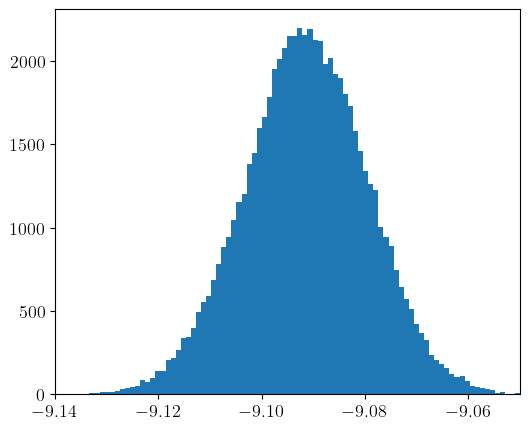

In [123]:
plt.hist(total_fvib_300,bins=2000);
plt.xlim([-9.14,-9.05])

65958
65949
300 K <H>: -7.838594348037272
-1505.39610441
19333


100%|████████████████████████████████████████████████████████████████████████████████| 19332/19332 [00:02<00:00, 9322.33it/s]


-TS_{conf} (DFT): -0.25276880519525957


100%|███████████████████████████████████████████████████████████████████████████████| 65948/65948 [00:05<00:00, 11417.10it/s]


S_{conf}: 0.0009494200297353411
-TS_{conf}: -0.28482600892060234
G: -8.123420356957874


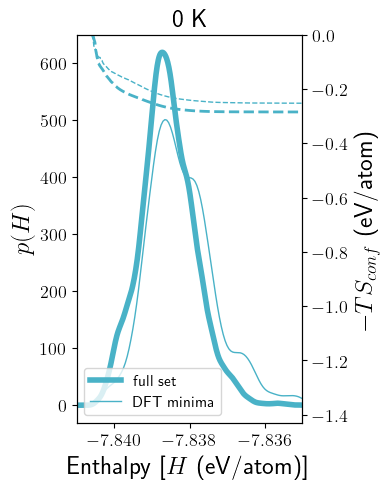

In [18]:
import math
k=8.6173303e-5

fig, ax1=plt.subplots(1,1,figsize=(4,5))
#fig.subplots_adjust(wspace=0.3)  # adjust space between Axes
print(len(local_minima))
Natoms=56+96+24+16

local_minima_cleared=[_x/Natoms for _x in local_minima if _x is not None]
print(len(local_minima_cleared))
local_minima_cleared=list(sorted(local_minima_cleared))
local_minima_cleared=np.array(local_minima_cleared)

xmin=min(local_minima_cleared)
E_exp=sum([j*math.exp(-(j-xmin)/(k*300)) for j in local_minima_cleared])/sum([math.exp(-(j-xmin)/(k*300)) for j in local_minima_cleared])
print("300 K <H>: "+str(E_exp))

kernel = st.gaussian_kde(local_minima_cleared)
x=np.arange(min(local_minima_cleared)-0.005,max(local_minima_cleared)+0.005,0.00001)
ax1.plot(x,kernel(x),'-',c='#49B2C7',lw=4,label='full set')


#=======================================
#DFT data
#=======================================

d=dict(np.load('./LLZO/llzo_11_45/opt_data_cLLZO_11_45_opt_partial_set_last_frame.npz',allow_pickle=True))
x=list(sorted(d['E']))
print(x[0])
x=[i/Natoms for i in x] 
dft_minima=x
min_e=min(x)
print(len(x))
kernel_DFT = st.gaussian_kde(x)
_x=np.arange(min(x)-0.002,max(x)+0.002,0.00005)
ax1.plot(_x,kernel_DFT(_x),'-',c='#49B2C7',lw=1,label='DFT minima')

ax1.set_xlim([-7.841,-7.835])
ax1.set_ylabel('$p(H)$')
ax1.set_xlabel('Enthalpy [$H$ (eV/atom)]')

free_energies=[]
xmin=min(x)
xx=np.array([i-xmin for i in x]) #partition function should be measured with respect to the global minimum in the ensemble
for i in trange(1,len(xx)):
    _xx=np.array(xx[:i])
    _zz=np.exp(-1.0*_xx/(300*k))
    Z=np.sum(_zz)
    #Z=np.sum([np.exp(-1.0*j/(300*k)) for j in xx[:i]])
    free_energies.append(-k*300*np.log(Z))
    
ax1_1 = ax1.twinx() 
ax1_1.plot(x[1:],free_energies,'--',lw=1,c='#49B2C7')
print('-TS_{conf} (DFT): '+str(free_energies[-1]))

#resampled_DFT=list(kernel_DFT.resample(size=65958))
#print(np.shape(resampled_DFT[0]))
#resampled_DFT=resampled_DFT[0]
#min_val=min(resampled_DFT)
#resampled_DFT=[i-min_val for i in resampled_DFT]
#resampled_DFT=np.array(list(sorted(resampled_DFT))[1:])
#_zz=np.exp(-1.0*resampled_DFT/(300*k))
#Z=np.sum(_zz)
#fe=-k*300*np.log(Z)
#print('-TS_{conf} (DFT resampled): '+str(fe))

#=======================================

#=======================================

free_energies=[]
xmin=min(local_minima_cleared)
xx=np.array([i-xmin for i in local_minima_cleared]) #partition function should be measured with respect to the global minimum in the ensemble
for i in trange(1,len(xx)):
    _xx=np.array(xx[:i])
    _zz=np.exp(-1.0*_xx/(300*k))
    Z=np.sum(_zz)
    #Z=np.sum([np.exp(-1.0*j/(300*k)) for j in xx[:i]])
    free_energies.append(-k*300*np.log(Z))

print('S_{conf}: '+str(free_energies[-1]/(-300)))
print('-TS_{conf}: '+str(free_energies[-1]))
print('G: '+str(free_energies[-1]+E_exp))
free_energies_0K=free_energies
ax1_1.plot(local_minima_cleared[1:],free_energies,'--',lw=2,c='#49B2C7')
ax1_1.set_ylim([-1.43,0.0])
ax1_1.set_ylabel('$-TS_{conf}$ (eV/atom)')

ax1.set_title('0 K')
ax1.legend(loc=3)
plt.tight_layout()

plt.savefig('11_45_H_fullset_distributions.pdf')

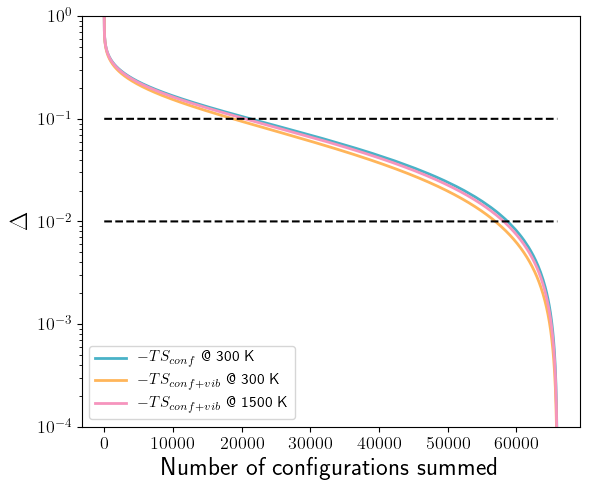

In [60]:
plt.plot([i for i in range(len(free_energies_0K))],[(i-free_energies_0K[-1])/abs(free_energies_0K[-1]) for i in free_energies_0K],'-',lw=2,c='#49B2C7',label='$-TS_{conf}$ @ 300 K')
plt.plot([i for i in range(len(free_energies_300K))],[(i-free_energies_300K[-1])/abs(free_energies_300K[-1]) for i in free_energies_300K],'-',lw=2,c='#FFB55A',label='$-TS_{conf+vib}$ @ 300 K')
plt.plot([i for i in range(len(free_energies_1500K))],[(i-free_energies_1500K[-1])/abs(free_energies_1500K[-1]) for i in free_energies_1500K],'-',lw=2,c='#F694BD',label='$-TS_{conf+vib}$ @ 1500 K')
plt.plot([i for i in range(len(free_energies_1500K))],[0.1 for _ in free_energies_1500K],'k--')
plt.plot([i for i in range(len(free_energies_1500K))],[0.01 for _ in free_energies_1500K],'k--')
plt.legend(loc=3)
plt.xlabel("Number of configurations summed")
plt.ylabel("$\Delta$")
plt.yscale('log')
plt.ylim([1e-4,1])
plt.tight_layout()
plt.savefig('configuration_sampling_convergence.pdf')

0.284469599743443
0.2844674914946689


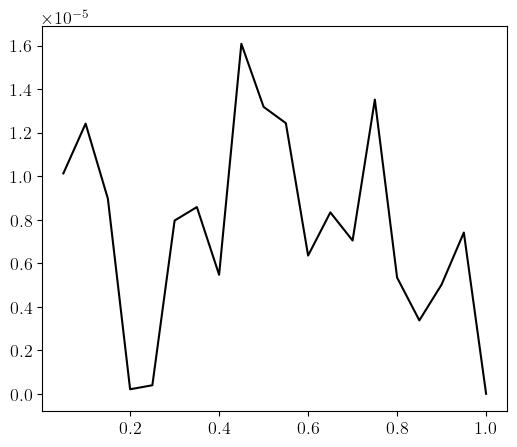

In [117]:
fe=[]
percentages=np.arange(0.05,1.05,0.05)
for percentage in percentages:
    _fe=[]
    for _ in range(20):
        limited_set=np.random.choice(dft_minima,size=int(percentage*len(dft_minima)))
        kernel = st.gaussian_kde(limited_set)
        limited_set = list(kernel.resample(size=65958))[0]
        xx=np.array([i-xmin for i in limited_set])
        _xx=np.array(xx[:i])
        _zz=np.exp(-1.0*_xx/(300*k))
        Z=np.sum(_zz)
        _fe.append(-k*300*np.log(Z))
        
    fe.append(np.mean(_fe))
    
print(abs(fe[-1]))
print(abs(fe[-2]))

plt.plot(percentages,[abs(i-fe[-1])/abs(fe[-1]) for i in fe],'k-')
